# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:
1. Якщо передати один суцільний рядок, BPE також зможе навчитися, але межі між віршами можуть загубитися. Без роздільників алгоритм може враховувати пари символів на стиках різних віршів.
2.
* Нормалізація — приведення тексту до потрібного формату.
* Попередня токенізація — поділ тексту на початкові частини.
* Токенізація — поділ частин на токени за алгоритмом BPE, WordPiece або Unigram.
* Постобробка — додавання спеціальних токенів за потреби.
* Кодування — перетворення токенів на числові ID.
3. <unk> позначає невідомий токен, а <eos> — кінець послідовності, зокрема вірша.
4. Менший словник зазвичай збільшує кількість токенів на вірш, оскільки слова частіше діляться на менші частини. Частка <unk> у ByteLevel BPE може залишатися нульовою, адже текст можна представити байтовими токенами. Фактичні значення потрібно визначити експериментально.
5. <eos> позначає кінець вірша. Без нього модель сприйматиме сусідні вірші як продовження одного тексту й не матиме явного маркера завершення.
6. train_data і val_data — одновимірні тензори torch.int64, елементи яких є числовими ID токенів. У моєму запуску вони містять відповідно 16 579 771 і 1 842 197 токенів.
7. assert xb.shape == yb.shape
assert xb.shape == (BATCH_SIZE, CONTEXT_LEN)
assert torch.equal(xb[:, 1:], yb[:, :-1])
8. Нижньотрикутна маска дозволяє враховувати лише поточні й попередні токени. Без неї модель могла б бачити майбутні токени під час навчання, що порушувало б принцип авторегресивної генерації.
9. Найкращий і останній чекпоінти збігаються, якщо найменший val_loss досягнуто наприкінці навчання. У моєму запуску найкращий чекпоінт — ітерація 7999 з val_loss = 5.653, тобто остання ітерація.
10. Зменшення EVAL_INTERVAL з 250 до 50 дає більше точок на графіку, але збільшує час оцінювання. Наскільки саме збільшиться час і чи стане графік інформативнішим, потрібно перевірити повторним запуском.
11. Температура ділить логіти перед softmax: \(p_i=\operatorname{softmax}(z_i/T)\). За низької температури модель частіше обирає найімовірніші токени, а за високої розподіл стає рівномірнішим і генерація — випадковішою.
12. top_p визначає сумарну ймовірність групи найімовірніших токенів, серед яких модель обирає наступний. Менше значення обмежує вибір, а більше зазвичай робить генерацію різноманітнішою.
13. За enable_thinking=True Qwen3 може генерувати блок міркувань перед відповіддю. Порівняно з False текст може стати довшим, а генерація — тривалішою. Конкретні зміни потрібно описати за результатом повторного запуску комірки 4.2.

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

In [17]:
!pip install -q datasets pandas

In [18]:
from datasets import load_dataset
import pandas as pd

dataset = load_dataset(
    "shamotskyi/ukr_pravda_2y",
    split="train"
)

news_df = dataset.to_pandas()

print("Кількість новин і колонок:", news_df.shape)
print("Назви колонок:", news_df.columns.tolist())
display(news_df.head(3))

README.md:   0%|          | 0.00/2.28k [00:00<?, ?B/s]

data/train/ukr_pravda_2y-0.0.2.csv: reconstructing file:   0%|          |  0.00B /  416MB            

data/train/ukr_pravda_2y-0.0.2.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/61629 [00:00<?, ? examples/s]

Кількість новин і колонок: (61629, 21)
Назви колонок: ['art_id', 'date_published', 'tags', 'ukr_uri', 'ukr_title', 'ukr_author_name', 'ukr_text', 'ukr_tags', 'ukr_tags_full', 'rus_uri', 'rus_title', 'rus_author_name', 'rus_text', 'rus_tags', 'rus_tags_full', 'eng_uri', 'eng_title', 'eng_author_name', 'eng_text', 'eng_tags', 'eng_tags_full']


,art_id,date_published,tags,ukr_uri,ukr_title,ukr_author_name,ukr_text,ukr_tags,ukr_tags_full,rus_uri,...,rus_author_name,rus_text,rus_tags,rus_tags_full,eng_uri,eng_title,eng_author_name,eng_text,eng_tags,eng_tags_full
0,7411594,2023-07-16,trivoga,https://www.pravda.com.ua/news/2023/07/16/7411...,У Києві та низці областей на 10 хвилин оголошу...,Катерина Тищенко,У Києві та ще низці регіонів України оголошува...,повітряна тривога,"[('trivoga', 'повітряна тривога', '/tags/trivo...",https://www.pravda.com.ua/rus/news/2023/07/16/...,...,Катерина Тищенко,В Киеве и еще ряде регионов Украины объявляли ...,воздушная тревога,"[('trivoga', 'воздушная тревога', '/rus/tags/t...",None,None,None,None,None,None
1,7339668,2022-04-14,"vijna,rosija,ukrajina,kijiv",https://www.pravda.com.ua/news/2022/04/14/7339...,"Київський готель Premier Palace спростовує, що...",Альона Мазуренко,Юрист столичного 5-зіркового готелю Premier Pa...,"Росія,Київ,Україна,війна","[('rosija', 'Росія', '/tags/rosija/'), ('kijiv...",https://www.pravda.com.ua/rus/news/2022/04/14/...,...,Алена Мазуренко,Юрист столичной 5-звездочной гостиницы Premier...,"Росcия,Киев,Украина,война","[('rosija', 'Росcия', '/rus/tags/rosija/'), ('...",None,None,None,None,None,None
2,7426798,2023-11-01,"vagner,ssha",https://www.pravda.com.ua/news/2023/11/1/7426798/,У Держдепі США стурбовані будь-якою активністю...,Тетяна Олійник,Речник Державного департаменту США Метью Мілле...,"США,Вагнер","[('ssha', 'США', '/tags/ssha/'), ('vagner', 'В...",https://www.pravda.com.ua/rus/news/2023/11/1/7...,...,Татьяна Олейник,Представитель Государственного департамента СШ...,"США,Вагнер","[('ssha', 'США', '/rus/tags/ssha/'), ('vagner'...",https://www.pravda.com.ua/eng/news/2023/11/1/7...,US State Department is concerned about any act...,Tetyana Oliynyk,"Matthew Miller, spokesman of the US State Depa...","USA,Wagner Group","[('ssha', 'USA', '/eng/tags/ssha/'), ('vagner'..."


In [19]:
print("Приклад новини:")
print(news_df["ukr_text"].iloc[0][:1000])

print("\nКількість порожніх текстів:")
print(news_df["ukr_text"].isna().sum())

Приклад новини:
У Києві та ще низці регіонів України оголошували повітряну тривогу через загрозу застосування балістичного озброєння. Джерело: alerts.in.ua, Повітряні сили Деталі: Близько 18:52 у столиці та інших регіонах оголосили повітряну тривогу. Пізніше Повітряні сили повідомили, що в Чернігівській, Київській, Сумській, Полтавській, Черкаській, Дніпропетровській, Донецькій, Запорізькій областях існує загроза застосування балістичного озброєння. Однак вже о 19:02 тривогу скасували майже в усіх областях.

Кількість порожніх текстів:
4403


In [20]:
# Залишаємо лише українські тексти новин
corpus_text = (
    news_df["ukr_text"]
    .dropna()
    .astype(str)
    .str.strip()
)

# Відкидаємо порожні тексти
corpus_text = corpus_text[corpus_text != ""].tolist()

print("Кількість новин:", len(corpus_text))
print("Загальна кількість символів:", sum(len(t) for t in corpus_text))
print("\nПриклад новини:")
print(corpus_text[0][:500])

Кількість новин: 57226
Загальна кількість символів: 81103480

Приклад новини:
У Києві та ще низці регіонів України оголошували повітряну тривогу через загрозу застосування балістичного озброєння. Джерело: alerts.in.ua, Повітряні сили Деталі: Близько 18:52 у столиці та інших регіонах оголосили повітряну тривогу. Пізніше Повітряні сили повідомили, що в Чернігівській, Київській, Сумській, Полтавській, Черкаській, Дніпропетровській, Донецькій, Запорізькій областях існує загроза застосування балістичного озброєння. Однак вже о 19:02 тривогу скасували майже в усіх областях.


In [21]:
from pathlib import Path
import numpy as np
import torch
import json
import os
import time

LAB_DIR = Path("/content/lab3")
MODELS_DIR = LAB_DIR / "models"
RUNS_DIR = LAB_DIR / "runs"
TOKENIZERS_DIR = LAB_DIR / "tokenizers"

for folder in [MODELS_DIR, RUNS_DIR, TOKENIZERS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Пристрій:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Новин у корпусі:", len(corpus_text))
print("Загальна кількість символів:", sum(len(text) for text in corpus_text))

Пристрій: cuda
GPU: Tesla T4
Новин у корпусі: 57226
Загальна кількість символів: 81103480


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

In [22]:
!pip install -q transformers tokenizers

In [23]:

import os
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
from tokenizers.normalizers import NFKC

# Фіксуємо випадковість для відтворюваності експериментів
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Папки для результатів лабораторної роботи
LAB_DIR = Path("/content/lab3")
MODELS_DIR = LAB_DIR / "models"
RUNS_DIR = LAB_DIR / "runs"
TOKENIZERS_DIR = LAB_DIR / "tokenizers"

for folder in [MODELS_DIR, RUNS_DIR, TOKENIZERS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("PyTorch:", torch.__version__)
print("Пристрій:", device)

if torch.cuda.is_available():
    print("Відеокарта:", torch.cuda.get_device_name(0))
else:
    print("GPU недоступний — навчання відбуватиметься на CPU.")

print("Папку результатів створено:", LAB_DIR)


PyTorch: 2.11.0+cu130
Пристрій: cuda
Відеокарта: Tesla T4
Папку результатів створено: /content/lab3


In [24]:
!pip install -q datasets

In [ ]:

dataset = load_dataset("shamotskyi/ukr_pravda_2y")

print(dataset)
print("\nДоступні частини датасету:", list(dataset.keys()))


DatasetDict({
    train: Dataset({
        features: ['art_id', 'date_published', 'tags', 'ukr_uri', 'ukr_title', 'ukr_author_name', 'ukr_text', 'ukr_tags', 'ukr_tags_full', 'rus_uri', 'rus_title', 'rus_author_name', 'rus_text', 'rus_tags', 'rus_tags_full', 'eng_uri', 'eng_title', 'eng_author_name', 'eng_text', 'eng_tags', 'eng_tags_full'],
        num_rows: 61629
    })
})

Доступні частини датасету: ['train']


In [27]:
# Перевіряємо тип датасету та отримуємо DataFrame

if hasattr(dataset, "to_pandas"):
    # Якщо dataset — один Dataset
    news_df = dataset.to_pandas()

elif "train" in dataset:
    # Якщо dataset — DatasetDict із розділами
    news_df = dataset["train"].to_pandas()

else:
    # Якщо є кілька розділів, беремо перший
    first_split = list(dataset.keys())[0]
    news_df = dataset[first_split].to_pandas()

print("Розмір датасету:", news_df.shape)
print("Колонки:", news_df.columns.tolist())


Розмір датасету: (61629, 21)
Колонки: ['art_id', 'date_published', 'tags', 'ukr_uri', 'ukr_title', 'ukr_author_name', 'ukr_text', 'ukr_tags', 'ukr_tags_full', 'rus_uri', 'rus_title', 'rus_author_name', 'rus_text', 'rus_tags', 'rus_tags_full', 'eng_uri', 'eng_title', 'eng_author_name', 'eng_text', 'eng_tags', 'eng_tags_full']


In [28]:

from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
from tokenizers.normalizers import NFKC
from pathlib import Path
import pandas as pd
import numpy as np
import json
import time

LAB_DIR = Path("/content/lab3")
MODELS_DIR = LAB_DIR / "models"
RUNS_DIR = LAB_DIR / "runs"
TOKENIZERS_DIR = LAB_DIR / "tokenizers"

for folder in [MODELS_DIR, RUNS_DIR, TOKENIZERS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

TOKENIZER_CORPUS_SIZE = min(10_000, len(corpus_text))
TOKENIZER_VOCAB_SIZE = 500
tokenizer_corpus = corpus_text[:TOKENIZER_CORPUS_SIZE]

def train_bpe(texts, vocab_size=500):
    tokenizer = Tokenizer(models.BPE(unk_token="[UNK]"))
    tokenizer.normalizer = NFKC()
    tokenizer.pre_tokenizer = pre_tokenizers.Metaspace(
        replacement="▁",
        prepend_scheme="always"
    )
    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        min_frequency=2,
        special_tokens=["[UNK]", "[EOS]"]
    )
    tokenizer.train_from_iterator(texts, trainer=trainer)
    tokenizer.decoder = decoders.Metaspace(
        replacement="▁",
        prepend_scheme="always"
    )
    return tokenizer

def train_wordpiece(texts, vocab_size=500):
    tokenizer = Tokenizer(models.WordPiece(unk_token="[UNK]"))
    tokenizer.normalizer = NFKC()
    tokenizer.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
    trainer = trainers.WordPieceTrainer(
        vocab_size=vocab_size,
        min_frequency=2,
        special_tokens=["[UNK]", "[EOS]"]
    )
    tokenizer.train_from_iterator(texts, trainer=trainer)
    tokenizer.decoder = decoders.WordPiece(prefix="##")
    return tokenizer

def train_unigram(texts, vocab_size=500):
    tokenizer = Tokenizer(models.Unigram())
    tokenizer.normalizer = NFKC()
    tokenizer.pre_tokenizer = pre_tokenizers.Metaspace(
        replacement="▁",
        prepend_scheme="always"
    )
    trainer = trainers.UnigramTrainer(
        vocab_size=vocab_size,
        special_tokens=["[UNK]", "[EOS]"],
        unk_token="[UNK]"
    )
    tokenizer.train_from_iterator(texts, trainer=trainer)
    tokenizer.decoder = decoders.Metaspace(
        replacement="▁",
        prepend_scheme="always"
    )
    return tokenizer

tokenizers_dict = {}

for name, function in [
    ("BPE", train_bpe),
    ("WordPiece", train_wordpiece),
    ("Unigram", train_unigram)
]:
    print(f"\nНавчання {name}...")
    tok = function(tokenizer_corpus, TOKENIZER_VOCAB_SIZE)
    tokenizers_dict[name] = tok
    tok.save(str(TOKENIZERS_DIR / f"{name.lower()}_tokenizer.json"))
    print("Розмір словника:", tok.get_vocab_size())
    print("Токенізатор збережено.")

print("\nУсі три токенізатори навчені.")



Навчання BPE...
Розмір словника: 500
Токенізатор збережено.

Навчання WordPiece...
Розмір словника: 661
Токенізатор збережено.

Навчання Unigram...
Розмір словника: 500
Токенізатор збережено.

Усі три токенізатори навчені.


In [29]:

sample_texts = corpus_text[:100]
comparison = []

for name, tok in tokenizers_dict.items():
    total_tokens = sum(len(tok.encode(text).ids) for text in sample_texts)
    total_chars = sum(len(text) for text in sample_texts)

    comparison.append({
        "Tokenizer": name,
        "Vocab size": tok.get_vocab_size(),
        "Tokens for 100 news": total_tokens,
        "Characters per token": round(
            total_chars / max(total_tokens, 1), 3
        )
    })

tokenizer_results = pd.DataFrame(comparison)
display(tokenizer_results)

tokenizer_results.to_csv(
    LAB_DIR / "tokenizer_comparison.csv",
    index=False
)
print("Таблицю збережено:", LAB_DIR / "tokenizer_comparison.csv")


,Tokenizer,Vocab size,Tokens for 100 news,Characters per token
0,BPE,500,88011,1.617
1,WordPiece,661,123049,1.157
2,Unigram,500,89891,1.583


Таблицю збережено: /content/lab3/tokenizer_comparison.csv


In [30]:

gpt_tokenizer = tokenizers_dict["BPE"]

EOS_ID = gpt_tokenizer.token_to_id("[EOS]")
UNK_ID = gpt_tokenizer.token_to_id("[UNK]")
VOCAB_SIZE = gpt_tokenizer.get_vocab_size()

assert EOS_ID is not None, "Токен [EOS] не знайдено"
assert UNK_ID is not None, "Токен [UNK] не знайдено"

test_text = corpus_text[0][:300]
encoded = gpt_tokenizer.encode(test_text)
decoded = gpt_tokenizer.decode(encoded.ids)

print("Розмір словника:", VOCAB_SIZE)
print("ID токена [EOS]:", EOS_ID)
print("Кількість токенів у прикладі:", len(encoded.ids))
print("\nОригінал:\n", test_text)
print("\nПісля декодування:\n", decoded)

gpt_tokenizer.save(str(TOKENIZERS_DIR / "minigpt_tokenizer.json"))
print("\nТокенізатор для MiniGPT збережено.")


Розмір словника: 500
ID токена [EOS]: 1
Кількість токенів у прикладі: 189

Оригінал:
 У Києві та ще низці регіонів України оголошували повітряну тривогу через загрозу застосування балістичного озброєння. Джерело: alerts.in.ua, Повітряні сили Деталі: Близько 18:52 у столиці та інших регіонах оголосили повітряну тривогу. Пізніше Повітряні сили повідомили, що в Чернігівській, Київській,

Після декодування:
 У Києві та ще низці регіонів України оголошували повітряну тривогу через загрозу застосування балістичного озброєння. Джерело: alerts.in.ua, Повітряні сили Деталі: Близько 18:52 у столиці та інших регіонах оголосили повітряну тривогу. Пізніше Повітряні сили повідомили, що в Чернігівській, Київській,

Токенізатор для MiniGPT збережено.


In [31]:

import numpy as np
import torch
import time

token_chunks = []
BATCH_SIZE_TOKENIZE = 128
start_time = time.time()

for start in range(0, len(corpus_text), BATCH_SIZE_TOKENIZE):
    batch_texts = corpus_text[start:start + BATCH_SIZE_TOKENIZE]
    encodings = gpt_tokenizer.encode_batch(batch_texts)

    batch_ids = [
        token_id
        for encoding in encodings
        for token_id in (*encoding.ids, EOS_ID)
    ]

    token_chunks.append(np.asarray(batch_ids, dtype=np.int32))

    if (start // BATCH_SIZE_TOKENIZE) % 50 == 0:
        print(
            f"Оброблено {min(start + BATCH_SIZE_TOKENIZE, len(corpus_text))}"
            f" / {len(corpus_text)} новин"
        )

all_token_ids = np.concatenate(token_chunks)

np.save(LAB_DIR / "news_token_ids.npy", all_token_ids)

print("\nКодування завершено.")
print("Кількість токенів:", len(all_token_ids))
print("Тип даних:", all_token_ids.dtype)
print(f"Час виконання: {(time.time() - start_time) / 60:.2f} хв")
print("Файл збережено:", LAB_DIR / "news_token_ids.npy")


Оброблено 128 / 57226 новин
Оброблено 6528 / 57226 новин
Оброблено 12928 / 57226 новин
Оброблено 19328 / 57226 новин
Оброблено 25728 / 57226 новин
Оброблено 32128 / 57226 новин
Оброблено 38528 / 57226 новин
Оброблено 44928 / 57226 новин
Оброблено 51328 / 57226 новин

Кодування завершено.
Кількість токенів: 50278081
Тип даних: int32
Час виконання: 1.92 хв
Файл збережено: /content/lab3/news_token_ids.npy


In [32]:

# Розділяємо послідовність токенів у співвідношенні 90% / 10%
split_idx = int(len(all_token_ids) * 0.9)

train_ids = all_token_ids[:split_idx]
val_ids = all_token_ids[split_idx:]

train_data = torch.tensor(train_ids, dtype=torch.long)
val_data = torch.tensor(val_ids, dtype=torch.long)

print("Train токенів:", len(train_data))
print("Validation токенів:", len(val_data))
print("Частка train:", round(len(train_data) / len(all_token_ids), 3))
print("Частка validation:", round(len(val_data) / len(all_token_ids), 3))
print("VOCAB_SIZE:", VOCAB_SIZE)
print("EOS_ID:", EOS_ID)

assert len(train_data) > 1000
assert len(val_data) > 1000
assert train_data.min() >= 0
assert train_data.max() < VOCAB_SIZE
assert val_data.min() >= 0
assert val_data.max() < VOCAB_SIZE

print("Перевірки пройдено.")


Train токенів: 45250272
Validation токенів: 5027809
Частка train: 0.9
Частка validation: 0.1
VOCAB_SIZE: 500
EOS_ID: 1
Перевірки пройдено.


In [33]:

import shutil
from pathlib import Path
import numpy as np

DRIVE_LAB_DIR = Path("/content/drive/MyDrive/lab3")
DRIVE_MODELS_DIR = DRIVE_LAB_DIR / "models"
DRIVE_RUNS_DIR = DRIVE_LAB_DIR / "runs"
DRIVE_TOKENIZERS_DIR = DRIVE_LAB_DIR / "tokenizers"

for folder in [DRIVE_MODELS_DIR, DRIVE_RUNS_DIR, DRIVE_TOKENIZERS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Копіюємо CSV, не видаляючи локальну копію
shutil.copy2(
    LAB_DIR / "tokenizer_comparison.csv",
    DRIVE_LAB_DIR / "tokenizer_comparison.csv"
)

# Копіюємо всі токенізатори
for path in TOKENIZERS_DIR.glob("*.json"):
    shutil.copy2(path, DRIVE_TOKENIZERS_DIR / path.name)

# Зберігаємо закодовані дані на Google Drive
np.save(DRIVE_LAB_DIR / "news_token_ids.npy", all_token_ids)

print("Збереження завершено!")
print("Папка:", DRIVE_LAB_DIR)
print("CSV:", (DRIVE_LAB_DIR / "tokenizer_comparison.csv").exists())
print("Токенізатори:", [p.name for p in DRIVE_TOKENIZERS_DIR.glob("*.json")])
print("Файл токенів:", (DRIVE_LAB_DIR / "news_token_ids.npy").exists())


Збереження завершено!
Папка: /content/drive/MyDrive/lab3
CSV: True
Токенізатори: ['minigpt_tokenizer.json', 'wordpiece_tokenizer.json', 'bpe_tokenizer.json', 'unigram_tokenizer.json']
Файл токенів: True


In [34]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# Параметри першої моделі
CONTEXT_LEN = 64
EMBED_DIM = 64
N_HEADS = 4
N_LAYERS = 2
DROPOUT = 0.1
BATCH_SIZE = 16
LEARNING_RATE = 3e-4
MAX_ITERS = 500
EVAL_INTERVAL = 100
EVAL_ITERS = 10

assert EMBED_DIM % N_HEADS == 0

class AttentionHead(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(EMBED_DIM, head_size, bias=False)
        self.query = nn.Linear(EMBED_DIM, head_size, bias=False)
        self.value = nn.Linear(EMBED_DIM, head_size, bias=False)
        self.register_buffer(
            "tril",
            torch.tril(torch.ones(CONTEXT_LEN, CONTEXT_LEN))
        )
        self.dropout = nn.Dropout(DROPOUT)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)
        weights = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5)
        weights = weights.masked_fill(
            self.tril[:T, :T] == 0, float("-inf")
        )
        weights = F.softmax(weights, dim=-1)
        weights = self.dropout(weights)
        return weights @ self.value(x)

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([
            AttentionHead(head_size) for _ in range(num_heads)
        ])
        self.proj = nn.Linear(num_heads * head_size, EMBED_DIM)
        self.dropout = nn.Dropout(DROPOUT)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))

class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(EMBED_DIM, 4 * EMBED_DIM),
            nn.ReLU(),
            nn.Linear(4 * EMBED_DIM, EMBED_DIM),
            nn.Dropout(DROPOUT)
        )

    def forward(self, x):
        return self.net(x)

class TransformerBlock(nn.Module):
    def __init__(self):
        super().__init__()
        head_size = EMBED_DIM // N_HEADS
        self.sa = MultiHeadAttention(N_HEADS, head_size)
        self.ffwd = FeedForward()
        self.ln1 = nn.LayerNorm(EMBED_DIM)
        self.ln2 = nn.LayerNorm(EMBED_DIM)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

class MiniGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(VOCAB_SIZE, EMBED_DIM)
        self.position_embedding_table = nn.Embedding(CONTEXT_LEN, EMBED_DIM)
        self.blocks = nn.Sequential(*[
            TransformerBlock() for _ in range(N_LAYERS)
        ])
        self.ln_f = nn.LayerNorm(EMBED_DIM)
        self.lm_head = nn.Linear(EMBED_DIM, VOCAB_SIZE)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(
            torch.arange(T, device=idx.device)
        )
        x = tok_emb + pos_emb
        x = self.blocks(x)
        logits = self.lm_head(self.ln_f(x))

        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(
                logits.reshape(B * T, C),
                targets.reshape(B * T)
            )
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -CONTEXT_LEN:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            next_idx = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, next_idx), dim=1)
        return idx

model = MiniGPT().to(device)

print("Модель створена.")
print("Пристрій:", device)
print("Кількість параметрів:", sum(p.numel() for p in model.parameters()))


Модель створена.
Пристрій: cuda
Кількість параметрів: 168308


In [35]:

train_data = torch.tensor(train_ids, dtype=torch.long)
val_data = torch.tensor(val_ids, dtype=torch.long)

def get_batch(split):
    data = train_data if split == "train" else val_data

    ix = torch.randint(
        len(data) - CONTEXT_LEN - 1,
        (BATCH_SIZE,)
    )

    x = torch.stack([
        data[i:i + CONTEXT_LEN] for i in ix
    ])
    y = torch.stack([
        data[i + 1:i + CONTEXT_LEN + 1] for i in ix
    ])

    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss():
    model.eval()
    results = {}

    for split in ["train", "val"]:
        losses = torch.zeros(EVAL_ITERS)

        for k in range(EVAL_ITERS):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()

        results[split] = losses.mean().item()

    model.train()
    return results

xb, yb = get_batch("train")

print("X shape:", xb.shape)
print("Y shape:", yb.shape)
print("Пристрій батчу:", xb.device)
print("Початкове оцінювання:", estimate_loss())


X shape: torch.Size([16, 64])
Y shape: torch.Size([16, 64])
Пристрій батчу: cuda:0
Початкове оцінювання: {'train': 6.394525051116943, 'val': 6.396058082580566}


In [36]:

from torch.utils.tensorboard import SummaryWriter

V1_RUN_DIR = RUNS_DIR / "mini_gpt_v1"
V1_RUN_DIR.mkdir(parents=True, exist_ok=True)

writer = SummaryWriter(log_dir=str(V1_RUN_DIR))
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

best_val_loss = float("inf")
history_v1 = []
start_time = time.time()

# Оцінювання перед навчанням
initial_losses = estimate_loss()
print(
    f"До навчання: train_loss={initial_losses['train']:.4f}, "
    f"val_loss={initial_losses['val']:.4f}"
)

for iteration in range(MAX_ITERS):
    model.train()

    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if iteration % EVAL_INTERVAL == 0 or iteration == MAX_ITERS - 1:
        losses = estimate_loss()

        record = {
            "iteration": iteration,
            "train_loss": losses["train"],
            "val_loss": losses["val"]
        }
        history_v1.append(record)

        writer.add_scalar("Loss/train", losses["train"], iteration)
        writer.add_scalar("Loss/validation", losses["val"], iteration)

        print(
            f"Ітерація {iteration:3d} | "
            f"train_loss={losses['train']:.4f} | "
            f"val_loss={losses['val']:.4f}"
        )

        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]

            torch.save({
                "iteration": iteration,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": best_val_loss,
                "config": {
                    "context_len": CONTEXT_LEN,
                    "embed_dim": EMBED_DIM,
                    "n_heads": N_HEADS,
                    "n_layers": N_LAYERS,
                    "dropout": DROPOUT,
                    "vocab_size": VOCAB_SIZE,
                    "eos_id": EOS_ID
                }
            }, MODELS_DIR / "minigpt_v1.pt")

writer.close()

with open(LAB_DIR / "history_v1.json", "w", encoding="utf-8") as f:
    json.dump(history_v1, f, ensure_ascii=False, indent=2)

shutil.copy2(
    MODELS_DIR / "minigpt_v1.pt",
    DRIVE_MODELS_DIR / "minigpt_v1.pt"
)
shutil.copy2(
    LAB_DIR / "history_v1.json",
    DRIVE_LAB_DIR / "history_v1.json"
)

print("\nНавчання завершено.")
print(f"Найкращий val_loss: {best_val_loss:.4f}")
print(f"Час: {(time.time() - start_time) / 60:.2f} хв")
print("Checkpoint:", MODELS_DIR / "minigpt_v1.pt")
print("Копія на Google Drive:", DRIVE_MODELS_DIR / "minigpt_v1.pt")


До навчання: train_loss=6.3990, val_loss=6.3985
Ітерація   0 | train_loss=6.3938 | val_loss=6.3789
Ітерація 100 | train_loss=5.0440 | val_loss=5.0560
Ітерація 200 | train_loss=4.9401 | val_loss=4.9678
Ітерація 300 | train_loss=4.8593 | val_loss=4.8546
Ітерація 400 | train_loss=4.6897 | val_loss=4.6454
Ітерація 499 | train_loss=4.4512 | val_loss=4.4690

Навчання завершено.
Найкращий val_loss: 4.4690
Час: 0.33 хв
Checkpoint: /content/lab3/models/minigpt_v1.pt
Копія на Google Drive: /content/drive/MyDrive/lab3/models/minigpt_v1.pt


In [37]:

# Генеруємо текст навченою моделлю
model.eval()

prompt = "Україна"
prompt_ids = gpt_tokenizer.encode(prompt).ids

context = torch.tensor(
    [prompt_ids],
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    generated_ids = model.generate(context, max_new_tokens=100)

generated_text = gpt_tokenizer.decode(
    generated_ids[0].tolist()
)

print("Початковий текст:", prompt)
print("\nЗгенерований текст:\n")
print(generated_text)


Початковий текст: Україна

Згенерований текст:

Україна0ютькад додадастіраюнра гала 2ють роринзо 🇺нулатараzзля тарід Украї\новач  проm Кріш буж Рлерягоцві втатанняере, мипемастe на від насвоми д не,аліниря рійї пі одибі Ппудая. 9


In [38]:

import shutil
import json
from pathlib import Path

DRIVE_LAB_DIR = Path("/content/drive/MyDrive/lab3")
DRIVE_MODELS_DIR = DRIVE_LAB_DIR / "models"
DRIVE_RUNS_DIR = DRIVE_LAB_DIR / "runs"
DRIVE_TOKENIZERS_DIR = DRIVE_LAB_DIR / "tokenizers"

for folder in [DRIVE_MODELS_DIR, DRIVE_RUNS_DIR, DRIVE_TOKENIZERS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Копіюємо модель v1
shutil.copy2(
    LAB_DIR / "models" / "minigpt_v1.pt",
    DRIVE_MODELS_DIR / "minigpt_v1.pt"
)

# Зберігаємо історію навчання
with open(LAB_DIR / "history_v1.json", "w", encoding="utf-8") as f:
    json.dump(history_v1, f, ensure_ascii=False, indent=2)

shutil.copy2(
    LAB_DIR / "history_v1.json",
    DRIVE_LAB_DIR / "history_v1.json"
)

# Зберігаємо результати токенізаторів
shutil.copy2(
    LAB_DIR / "tokenizer_comparison.csv",
    DRIVE_LAB_DIR / "tokenizer_comparison.csv"
)

# Перевіряємо, що модель справді збережена
checkpoint_path = DRIVE_MODELS_DIR / "minigpt_v1.pt"

print("Модель v1 збережена:", checkpoint_path.exists())
print("Розмір файлу:", round(checkpoint_path.stat().st_size / 1024**2, 2), "МБ")
print("Історія навчання збережена:", (DRIVE_LAB_DIR / "history_v1.json").exists())


Модель v1 збережена: True
Розмір файлу: 2.11 МБ
Історія навчання збережена: True


In [39]:

from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
from tokenizers.normalizers import NFKC
from pathlib import Path
import shutil

# Налаштування нового токенізатора
V2_VOCAB_SIZE = 4000

def train_bpe_v2(texts, vocab_size=4000):
    tokenizer = Tokenizer(models.BPE(unk_token="[UNK]"))
    tokenizer.normalizer = NFKC()
    tokenizer.pre_tokenizer = pre_tokenizers.Metaspace(
        replacement="▁",
        prepend_scheme="always"
    )

    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        min_frequency=2,
        special_tokens=["[UNK]", "[EOS]"]
    )

    tokenizer.train_from_iterator(texts, trainer=trainer)
    tokenizer.decoder = decoders.Metaspace(
        replacement="▁",
        prepend_scheme="always"
    )
    return tokenizer

# Навчаємо на тих самих 10 000 новинах
tokenizer_v2 = train_bpe_v2(
    corpus_text[:min(10_000, len(corpus_text))],
    V2_VOCAB_SIZE
)

# Зберігаємо окремо, не перезаписуючи токенізатор v1
v2_tokenizer_path = TOKENIZERS_DIR / "minigpt_v2_tokenizer.json"
tokenizer_v2.save(str(v2_tokenizer_path))

# Копія на Google Drive
shutil.copy2(
    v2_tokenizer_path,
    DRIVE_TOKENIZERS_DIR / "minigpt_v2_tokenizer.json"
)

V2_VOCAB_SIZE = tokenizer_v2.get_vocab_size()
V2_EOS_ID = tokenizer_v2.token_to_id("[EOS]")

print("Токенізатор v2 навчено.")
print("Розмір словника:", V2_VOCAB_SIZE)
print("ID токена EOS:", V2_EOS_ID)
print("Збережено на Drive:", (DRIVE_TOKENIZERS_DIR / "minigpt_v2_tokenizer.json").exists())


Токенізатор v2 навчено.
Розмір словника: 4000
ID токена EOS: 1
Збережено на Drive: True


In [40]:

import numpy as np
import torch
import shutil

V2_TOKEN_BATCH_SIZE = 128
v2_token_chunks = []

for start in range(0, len(corpus_text), V2_TOKEN_BATCH_SIZE):
    batch_texts = corpus_text[start:start + V2_TOKEN_BATCH_SIZE]
    encodings = tokenizer_v2.encode_batch(batch_texts)

    batch_ids = [
        token_id
        for encoding in encodings
        for token_id in (*encoding.ids, V2_EOS_ID)
    ]

    v2_token_chunks.append(np.asarray(batch_ids, dtype=np.int32))

    if start % 6400 == 0:
        print(f"Оброблено новин: {min(start + V2_TOKEN_BATCH_SIZE, len(corpus_text))}/{len(corpus_text)}")

v2_all_token_ids = np.concatenate(v2_token_chunks)

# Зберігаємо закодований корпус окремо від v1
v2_tokens_path = LAB_DIR / "news_token_ids_v2.npy"
np.save(v2_tokens_path, v2_all_token_ids)

shutil.copy2(
    v2_tokens_path,
    DRIVE_LAB_DIR / "news_token_ids_v2.npy"
)

# Розділення 90% / 10%
v2_split_idx = int(len(v2_all_token_ids) * 0.9)

v2_train_ids = v2_all_token_ids[:v2_split_idx]
v2_val_ids = v2_all_token_ids[v2_split_idx:]

# Перевірка меж значень
assert v2_all_token_ids.min() >= 0
assert v2_all_token_ids.max() < V2_VOCAB_SIZE
assert len(v2_train_ids) > 0 and len(v2_val_ids) > 0

print("\nТокенізацію v2 завершено.")
print("Усього токенів:", len(v2_all_token_ids))
print("Навчальних токенів:", len(v2_train_ids))
print("Валідаційних токенів:", len(v2_val_ids))
print("Розмір словника:", V2_VOCAB_SIZE)
print("Максимальний ID:", int(v2_all_token_ids.max()))
print("Файл на Google Drive:", (DRIVE_LAB_DIR / "news_token_ids_v2.npy").exists())


Оброблено новин: 128/57226
Оброблено новин: 6528/57226
Оброблено новин: 12928/57226
Оброблено новин: 19328/57226
Оброблено новин: 25728/57226
Оброблено новин: 32128/57226
Оброблено новин: 38528/57226
Оброблено новин: 44928/57226
Оброблено новин: 51328/57226

Токенізацію v2 завершено.
Усього токенів: 22450095
Навчальних токенів: 20205085
Валідаційних токенів: 2245010
Розмір словника: 4000
Максимальний ID: 3999
Файл на Google Drive: True


In [41]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# Налаштування v2 — окремі від v1
V2_CONTEXT_LEN = 128
V2_EMBED_DIM = 128
V2_N_HEADS = 4
V2_N_LAYERS = 4
V2_DROPOUT = 0.1

V2_BATCH_SIZE = 32
V2_LEARNING_RATE = 3e-4
V2_MAX_ITERS = 3000
V2_EVAL_INTERVAL = 300
V2_EVAL_ITERS = 20

assert V2_EMBED_DIM % V2_N_HEADS == 0

class AttentionHeadV2(nn.Module):
    def __init__(self, head_size, embed_dim, context_len, dropout):
        super().__init__()
        self.key = nn.Linear(embed_dim, head_size, bias=False)
        self.query = nn.Linear(embed_dim, head_size, bias=False)
        self.value = nn.Linear(embed_dim, head_size, bias=False)
        self.register_buffer(
            "tril",
            torch.tril(torch.ones(context_len, context_len))
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)
        q = self.query(x)
        weights = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5)
        weights = weights.masked_fill(
            self.tril[:T, :T] == 0,
            float("-inf")
        )
        weights = F.softmax(weights, dim=-1)
        weights = self.dropout(weights)
        return self.dropout(weights @ self.value(x))


class MultiHeadAttentionV2(nn.Module):
    def __init__(self, num_heads, head_size, embed_dim, context_len, dropout):
        super().__init__()
        self.heads = nn.ModuleList([
            AttentionHeadV2(head_size, embed_dim, context_len, dropout)
            for _ in range(num_heads)
        ])
        self.proj = nn.Linear(num_heads * head_size, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(
            self.proj(torch.cat([head(x) for head in self.heads], dim=-1))
        )


class FeedForwardV2(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.GELU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlockV2(nn.Module):
    def __init__(self, embed_dim, num_heads, context_len, dropout):
        super().__init__()
        head_size = embed_dim // num_heads
        self.sa = MultiHeadAttentionV2(
            num_heads, head_size, embed_dim, context_len, dropout
        )
        self.ffwd = FeedForwardV2(embed_dim, dropout)
        self.ln1 = nn.LayerNorm(embed_dim)
        self.ln2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class MiniGPTv2(nn.Module):
    def __init__(
        self,
        vocab_size,
        context_len,
        embed_dim,
        num_heads,
        num_layers,
        dropout
    ):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlockV2(
                embed_dim, num_heads, context_len, dropout
            )
            for _ in range(num_layers)
        ])
        self.ln_f = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)
        pos = torch.arange(T, device=idx.device)
        x = tok_emb + self.position_embedding(pos)
        x = self.blocks(x)
        logits = self.lm_head(self.ln_f(x))

        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(
                logits.view(B * T, C),
                targets.view(B * T)
            )
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=40):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                values, _ = torch.topk(
                    logits, min(top_k, logits.shape[-1])
                )
                logits[logits < values[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, next_token), dim=1)
        return idx


model_v2 = MiniGPTv2(
    vocab_size=V2_VOCAB_SIZE,
    context_len=V2_CONTEXT_LEN,
    embed_dim=V2_EMBED_DIM,
    num_heads=V2_N_HEADS,
    num_layers=V2_N_LAYERS,
    dropout=V2_DROPOUT
).to(device)

v2_parameters = sum(p.numel() for p in model_v2.parameters() if p.requires_grad)

print("MiniGPT v2 створено.")
print("Пристрій:", device)
print("Розмір словника:", V2_VOCAB_SIZE)
print("Довжина контексту:", V2_CONTEXT_LEN)
print("Кількість параметрів:", f"{v2_parameters:,}")
print("Пам'ять GPU:", round(torch.cuda.memory_allocated() / 1024**2, 1), "МБ")


MiniGPT v2 створено.
Пристрій: cuda
Розмір словника: 4000
Довжина контексту: 128
Кількість параметрів: 1,836,192
Пам'ять GPU: 9147.7 МБ


In [42]:

# Перетворюємо токени v2 на тензори
v2_train_data = torch.tensor(v2_train_ids.astype(np.int64), dtype=torch.long)
v2_val_data = torch.tensor(v2_val_ids.astype(np.int64), dtype=torch.long)

def get_batch_v2(split):
    data = v2_train_data if split == "train" else v2_val_data
    ix = torch.randint(
        len(data) - V2_CONTEXT_LEN - 1,
        (V2_BATCH_SIZE,)
    )
    x = torch.stack([
        data[i:i + V2_CONTEXT_LEN] for i in ix
    ])
    y = torch.stack([
        data[i + 1:i + V2_CONTEXT_LEN + 1] for i in ix
    ])
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss_v2():
    model_v2.eval()
    results = {}

    for split in ["train", "val"]:
        losses = torch.zeros(V2_EVAL_ITERS)
        for k in range(V2_EVAL_ITERS):
            xb, yb = get_batch_v2(split)
            _, loss = model_v2(xb, yb)
            losses[k] = loss.item()
        results[split] = losses.mean().item()

    model_v2.train()
    return results

xb, yb = get_batch_v2("train")

print("X shape:", xb.shape)
print("Y shape:", yb.shape)
print("Пристрій:", xb.device)
print("Початкові втрати:", estimate_loss_v2())


X shape: torch.Size([32, 128])
Y shape: torch.Size([32, 128])
Пристрій: cuda:0
Початкові втрати: {'train': 8.462822914123535, 'val': 8.4630708694458}


In [43]:

from torch.utils.tensorboard import SummaryWriter
import time
import json
import shutil

V2_RUN_DIR = RUNS_DIR / "mini_gpt_v2"
V2_RUN_DIR.mkdir(parents=True, exist_ok=True)

writer_v2 = SummaryWriter(log_dir=str(V2_RUN_DIR))
optimizer_v2 = torch.optim.AdamW(
    model_v2.parameters(),
    lr=V2_LEARNING_RATE
)

best_v2_val_loss = float("inf")
history_v2 = []
start_v2 = time.time()

for iteration in range(V2_MAX_ITERS):
    model_v2.train()

    xb, yb = get_batch_v2("train")
    _, loss = model_v2(xb, yb)

    optimizer_v2.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model_v2.parameters(), 1.0)
    optimizer_v2.step()

    if iteration % V2_EVAL_INTERVAL == 0 or iteration == V2_MAX_ITERS - 1:
        losses = estimate_loss_v2()

        record = {
            "iteration": iteration,
            "train_loss": losses["train"],
            "val_loss": losses["val"]
        }
        history_v2.append(record)

        writer_v2.add_scalar("Loss/train", losses["train"], iteration)
        writer_v2.add_scalar("Loss/validation", losses["val"], iteration)

        print(
            f"Ітерація {iteration:4d} | "
            f"train_loss={losses['train']:.4f} | "
            f"val_loss={losses['val']:.4f}"
        )

        if losses["val"] < best_v2_val_loss:
            best_v2_val_loss = losses["val"]

            checkpoint = {
                "iteration": iteration,
                "model_state_dict": model_v2.state_dict(),
                "optimizer_state_dict": optimizer_v2.state_dict(),
                "val_loss": best_v2_val_loss,
                "config": {
                    "context_len": V2_CONTEXT_LEN,
                    "embed_dim": V2_EMBED_DIM,
                    "n_heads": V2_N_HEADS,
                    "n_layers": V2_N_LAYERS,
                    "dropout": V2_DROPOUT,
                    "vocab_size": V2_VOCAB_SIZE,
                    "eos_id": V2_EOS_ID
                }
            }

            torch.save(checkpoint, MODELS_DIR / "minigpt_v2.pt")
            shutil.copy2(
                MODELS_DIR / "minigpt_v2.pt",
                DRIVE_MODELS_DIR / "minigpt_v2.pt"
            )

writer_v2.close()

with open(LAB_DIR / "history_v2.json", "w", encoding="utf-8") as f:
    json.dump(history_v2, f, ensure_ascii=False, indent=2)

shutil.copy2(
    LAB_DIR / "history_v2.json",
    DRIVE_LAB_DIR / "history_v2.json"
)

# Копіюємо TensorBoard-логи на Drive
drive_v2_run_dir = DRIVE_RUNS_DIR / "mini_gpt_v2"
drive_v2_run_dir.mkdir(parents=True, exist_ok=True)

for path in V2_RUN_DIR.iterdir():
    if path.is_file():
        shutil.copy2(path, drive_v2_run_dir / path.name)

print("\nНавчання v2 завершено.")
print("Найкращий val_loss:", round(best_v2_val_loss, 4))
print("Час навчання:", round((time.time() - start_v2) / 60, 2), "хв")
print("Модель збережена:", (DRIVE_MODELS_DIR / "minigpt_v2.pt").exists())
print("Логи збережені:", drive_v2_run_dir)


Ітерація    0 | train_loss=8.4458 | val_loss=8.4459
Ітерація  300 | train_loss=7.2457 | val_loss=7.2438
Ітерація  600 | train_loss=6.5336 | val_loss=6.5425
Ітерація  900 | train_loss=5.8701 | val_loss=5.8718
Ітерація 1200 | train_loss=5.4675 | val_loss=5.4446
Ітерація 1500 | train_loss=5.2193 | val_loss=5.2136
Ітерація 1800 | train_loss=5.0684 | val_loss=5.0717
Ітерація 2100 | train_loss=4.9816 | val_loss=4.9804
Ітерація 2400 | train_loss=4.8985 | val_loss=4.8783
Ітерація 2700 | train_loss=4.8244 | val_loss=4.8534
Ітерація 2999 | train_loss=4.7875 | val_loss=4.7930

Навчання v2 завершено.
Найкращий val_loss: 4.793
Час навчання: 1.96 хв
Модель збережена: True
Логи збережені: /content/drive/MyDrive/lab3/runs/mini_gpt_v2


In [44]:

import torch

checkpoint_path_v2 = DRIVE_MODELS_DIR / "minigpt_v2.pt"

checkpoint_v2 = torch.load(
    checkpoint_path_v2,
    map_location=device,
    weights_only=False
)

model_v2.load_state_dict(checkpoint_v2["model_state_dict"])
model_v2.eval()

prompts = [
    "Україна",
    "Сьогодні в Києві",
    "Учені повідомили"
]

for prompt in prompts:
    prompt_ids = tokenizer_v2.encode(prompt).ids

    context = torch.tensor(
        [prompt_ids],
        dtype=torch.long,
        device=device
    )

    with torch.no_grad():
        generated_ids = model_v2.generate(
            context,
            max_new_tokens=100,
            temperature=0.7,
            top_k=40
        )

    generated_text = tokenizer_v2.decode(
        generated_ids[0].tolist()
    )

    print("=" * 70)
    print("Початок:", prompt)
    print(generated_text)
    print()


Початок: Україна
Україна отримала вступу. Нагадаємо: Президент Володимир Зеленський наголосив, що не не відпорати за словами президента РФ проти України такий республіками, якщо у тому що Росія. Як відомо, то виступають своїй, який маємося на своїйно визнає і вони з подійшівчитися не вільних заходів". Деталі: Він також не виступаючи в межах допустити відключення, зокрема загові, що це знеполо Будановому не в

Початок: Сьогодні в Києві
Сьогодні в Києві під час війни вдень відсі. Джерело: "Європейська правда", повідомляє "Європейська правда" з посиланням на телемановокргадведчу, який з посиланням на ntures Пряма мова: "Наша відс у відповідь про надання Україні таким чи, що в Україні. Раніше повідомлялося, прода в Києві, що ця радатися до відповідальності поїздкується звідно про ситуацію, щоб в Україні. Раніше ЗМІ, колишнімперед, що залучення. Заході в

Початок: Учені повідомили
Учені повідомили про виступити нападно до кінця, заставини такою". Деталі: Урування моглих на виїздних злочини 

,iteration,train_loss,val_loss
0,0,8.445819,8.445925
1,300,7.245744,7.243757
2,600,6.533582,6.542502
3,900,5.870099,5.871768
4,1200,5.467506,5.444560
5,1500,5.219346,5.213571
6,1800,5.068446,5.071683
7,2100,4.981589,4.980366
8,2400,4.898513,4.878308
9,2700,4.824353,4.853356


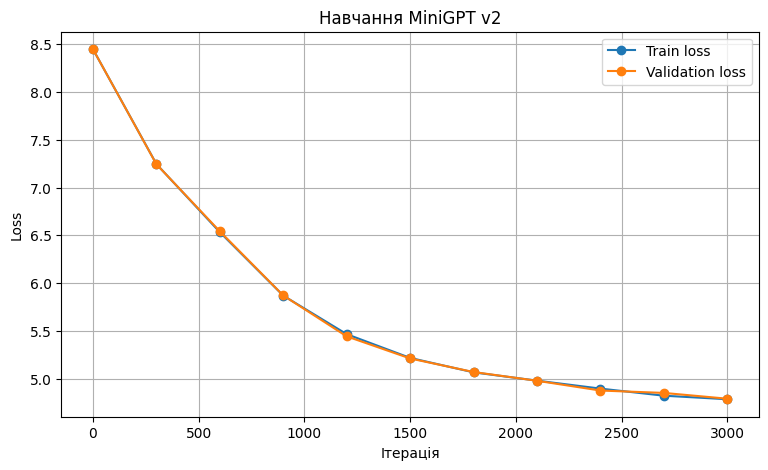

In [45]:

import pandas as pd
import matplotlib.pyplot as plt

history_v2_df = pd.DataFrame(history_v2)

display(history_v2_df)

plt.figure(figsize=(9, 5))
plt.plot(
    history_v2_df["iteration"],
    history_v2_df["train_loss"],
    marker="o",
    label="Train loss"
)
plt.plot(
    history_v2_df["iteration"],
    history_v2_df["val_loss"],
    marker="o",
    label="Validation loss"
)
plt.xlabel("Ітерація")
plt.ylabel("Loss")
plt.title("Навчання MiniGPT v2")
plt.legend()
plt.grid(True)
plt.show()


In [46]:

import torch
import time
import json
import shutil
from torch.utils.tensorboard import SummaryWriter

checkpoint_path_v2 = DRIVE_MODELS_DIR / "minigpt_v2.pt"

checkpoint_v2 = torch.load(
    checkpoint_path_v2,
    map_location=device,
    weights_only=False
)
model_v2.load_state_dict(checkpoint_v2["model_state_dict"])

optimizer_v2 = torch.optim.AdamW(
    model_v2.parameters(),
    lr=1e-4
)
if "optimizer_state_dict" in checkpoint_v2:
    optimizer_v2.load_state_dict(checkpoint_v2["optimizer_state_dict"])

# Зменшуємо learning rate для більш обережного продовження
for param_group in optimizer_v2.param_groups:
    param_group["lr"] = 1e-4

EXTRA_ITERS = 3000
EXTRA_EVAL_INTERVAL = 300
EXTRA_EVAL_ITERS = 20

# Для оцінювання використовуємо ту саму функцію, але 20 батчів
V2_EVAL_ITERS = EXTRA_EVAL_ITERS

writer_continue = SummaryWriter(
    log_dir=str(DRIVE_RUNS_DIR / "mini_gpt_v2_continue")
)

best_v2_val_loss = min(
    best_v2_val_loss,
    checkpoint_v2["val_loss"]
)
history_v2_continue = []
start_continue = time.time()

for step in range(EXTRA_ITERS):
    model_v2.train()
    xb, yb = get_batch_v2("train")
    _, loss = model_v2(xb, yb)

    optimizer_v2.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model_v2.parameters(), 1.0)
    optimizer_v2.step()

    if step % EXTRA_EVAL_INTERVAL == 0 or step == EXTRA_ITERS - 1:
        losses = estimate_loss_v2()
        iteration_total = V2_MAX_ITERS + step + 1

        history_v2_continue.append({
            "iteration": iteration_total,
            "train_loss": losses["train"],
            "val_loss": losses["val"]
        })

        writer_continue.add_scalar(
            "Loss/train", losses["train"], iteration_total
        )
        writer_continue.add_scalar(
            "Loss/validation", losses["val"], iteration_total
        )

        print(
            f"Ітерація {iteration_total} | "
            f"train_loss={losses['train']:.4f} | "
            f"val_loss={losses['val']:.4f}"
        )

        if losses["val"] < best_v2_val_loss:
            best_v2_val_loss = losses["val"]
            torch.save({
                "iteration": iteration_total,
                "model_state_dict": model_v2.state_dict(),
                "optimizer_state_dict": optimizer_v2.state_dict(),
                "val_loss": best_v2_val_loss,
                "config": checkpoint_v2["config"]
            }, MODELS_DIR / "minigpt_v2.pt")

            shutil.copy2(
                MODELS_DIR / "minigpt_v2.pt",
                DRIVE_MODELS_DIR / "minigpt_v2.pt"
            )

writer_continue.close()

print("\nПродовження завершено.")
print("Найкращий val_loss:", round(best_v2_val_loss, 4))
print("Час:", round((time.time() - start_continue) / 60, 2), "хв")


Ітерація 3001 | train_loss=4.7701 | val_loss=4.8015
Ітерація 3301 | train_loss=4.7363 | val_loss=4.7532
Ітерація 3601 | train_loss=4.7442 | val_loss=4.7346
Ітерація 3901 | train_loss=4.7253 | val_loss=4.7154
Ітерація 4201 | train_loss=4.7100 | val_loss=4.6963
Ітерація 4501 | train_loss=4.6727 | val_loss=4.6487
Ітерація 4801 | train_loss=4.6636 | val_loss=4.6928
Ітерація 5101 | train_loss=4.6462 | val_loss=4.6361
Ітерація 5401 | train_loss=4.6348 | val_loss=4.6366
Ітерація 5701 | train_loss=4.6503 | val_loss=4.6653
Ітерація 6000 | train_loss=4.6297 | val_loss=4.6212

Продовження завершено.
Найкращий val_loss: 4.6212
Час: 2.01 хв


In [47]:

checkpoint_v2 = torch.load(
    DRIVE_MODELS_DIR / "minigpt_v2.pt",
    map_location=device,
    weights_only=False
)

model_v2.load_state_dict(checkpoint_v2["model_state_dict"])
model_v2.eval()

print("Checkpoint з ітерації:", checkpoint_v2["iteration"])
print("Val loss:", checkpoint_v2["val_loss"])

prompts = [
    "Україна",
    "Сьогодні в Києві",
    "Учені повідомили"
]

for prompt in prompts:
    prompt_ids = tokenizer_v2.encode(prompt).ids
    context = torch.tensor(
        [prompt_ids],
        dtype=torch.long,
        device=device
    )

    with torch.no_grad():
        generated_ids = model_v2.generate(
            context,
            max_new_tokens=120,
            temperature=0.7,
            top_k=40
        )

    print("\n" + "=" * 70)
    print("Початок:", prompt)
    print(tokenizer_v2.decode(generated_ids[0].tolist()))


Checkpoint з ітерації: 6000
Val loss: 4.621188163757324

Початок: Україна
Україна може в НАТО, що це буде, що війна за даними УП, що є цінам, що вони не досеньків таємного конфлікту. Усі, що ми вже це важливо", – сказав він. Нагадаємо, і що на ним шляхом "ваючи наближення для того, що вони є ми єдитися, як ми в Україні, щоб в Україні, але це станемо, щоб не можемо. Наца сторона не будемомо ми повинні ми будемо, що їх не було вимо, як тільки", - сказав він. Нагадаємо, президент Володимир Зеленський заявив, що

Початок: Сьогодні в Києві
Сьогодні в Києві. Вранці 83 тисячі,73:30. Джерело: Генштаб ЗСУ Деталі: На Стрі, який з території Білорусі у Telegram-канал на Бахмутському напрямку українські захисники знищили обстріл з артилерії та реактивних БпЛА, Сіверському напрямка та мінометів. На Миколаївщина: ворог здійснив 4 ударів по районах населених пунктів Оріївка, Мар’їнках. На Мар’їнському напрямках противник завдав авіаційних ударів та Серені пункти та Новосії, мінометних обстрілів против

Під час експерименту було реалізовано та навчено дві версії MiniGPT на корпусі українських новин. Збільшення словника токенізатора з 500 до 4000 токенів і подальше навчання другої моделі знизили її валідаційні втрати з 8,446 до 4,621. Згенеровані тексти відтворюють окремі характерні конструкції новин, проте залишаються частково незв’язними. Це свідчить про обмежену якість генерації за використаного обсягу навчання та конфігурації моделі.

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

### 4.0. Запустіть приклади виконання різних NLP задач

In [48]:
!pip install "transformers[sentencepiece]==5.18.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 28.9 MB/s  0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.20.2
    Uninstalling transformers-5.20.2:
      Successfully uninstalled transformers-5.20.2


In [ ]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [ ]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [ ]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to use the following techniques:\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'}, {'generated_text': 'In this course, we will teach you how to use your knowledge to write a program that works for you.\n\n\n\nTo learn more about the language, read our course:\nEnglish, English, French, German, Spanish, Spanish, German, Dutch, German, German'}]


In [ ]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [ ]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [ ]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [ ]:
from transformers import pipeline

classifier = pipeline(
    "sentiment-analysis",
    model="lxyuan/distilbert-base-multilingual-cased-sentiments-student"
)

texts = [
    "Дуже гарні квіти, швидка доставка та чудове обслуговування!",
    "Рослина приїхала пошкодженою, а замовлення затримали."
]

print(classifier(texts))

config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

[{'label': 'positive', 'score': 0.8324486017227173}, {'label': 'negative', 'score': 0.6535537838935852}]


In [ ]:
from transformers import pipeline

classifier = pipeline(
    "zero-shot-classification",
    model="joeddav/xlm-roberta-large-xnli"
)

result = classifier(
    "Українські фермери розпочали весняну посадку овочів.",
    candidate_labels=[
        "сільське господарство",
        "спорт",
        "технології",
        "культура"
    ]
)

print(result)

config.json:   0%|          | 0.00/734 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

{'sequence': 'Українські фермери розпочали весняну посадку овочів.', 'labels': ['сільське господарство', 'спорт', 'технології', 'культура'], 'scores': [0.9751427173614502, 0.009226587601006031, 0.007945469580590725, 0.007685194257646799]}


In [4]:
# 3. Генерація україномовного тексту
from transformers import pipeline

generator = pipeline(
    "text-generation",
    model="ai-forever/mGPT"
)

result = generator(
    "Українські садівники навесні починають",
    max_new_tokens=40,
    num_return_sequences=1,
    do_sample=True,
    temperature=0.8
)

print(result[0]["generated_text"])

config.json:   0%|          | 0.00/738 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 3.45GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.45GB            

...

vocab.json:   0%|          | 0.00/1.89M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.20M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/606 [00:00<?, ?B/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Українські садівники навесні починають збирати зернові культури. Деякі сорти які почали відбирати, не вийшли на заміну. Але зараз


In [1]:
from transformers import pipeline

unmasker = pipeline(
    "fill-mask",
    model="FacebookAI/xlm-roberta-base"
)

result = unmasker(
    "Київ є столицею <mask>.",
    top_k=5
)

for item in result:
    print(item["token_str"], round(item["score"], 4))

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

України 0.7648
Європи 0.0968
світу 0.0231
Росії 0.0223
країни 0.0166


In [2]:
from transformers import pipeline

ner = pipeline(
    "ner",
    model="Davlan/xlm-roberta-base-ner-hrl",
    aggregation_strategy="simple"
)

text = (
    "Анастасія навчається в Житомирській політехніці "
    "та працює над вебпроєктом GreenBloom."
)

result = ner(text)

for entity in result:
    print(
        "Текст:", entity["word"],
        "| Тип:", entity["entity_group"],
        "| Оцінка:", round(float(entity["score"]), 4)
    )

config.json:   0%|          | 0.00/980 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/211 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Текст: Анастасія | Тип: PER | Оцінка: 0.9886
Текст: Житомирській політехніці | Тип: ORG | Оцінка: 0.9998


In [3]:
from transformers import pipeline

question_answerer = pipeline("table-question-answering")

table = {
    "Товар": ["Монстера", "Фікус", "Лаванда"],
    "Ціна": ["450", "520", "180"],
    "Категорія": ["Кімнатні рослини", "Кімнатні рослини", "Квіти"]
}

result = question_answerer(
    query="Яка ціна фікуса?",
    table=table
)

print(result)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

...

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': '520', 'coordinates': [(1, 1)], 'cells': ['520'], 'aggregator': 'NONE'}


---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [5]:
!pip install -q evaluate scikit-learn

In [6]:
texts = [
    "Дуже гарна рослина, швидка доставка!",
    "Замовлення прийшло вчасно, я задоволена.",
    "Чудовий магазин, обов'язково замовлю ще.",
    "Квіти свіжі, пакування якісне.",
    "Дуже привітний персонал і хороший сервіс.",
    "Насіння якісне, майже все проросло.",
    "Рослина гарна і здорова.",
    "Дякую за швидке оформлення замовлення.",
    "Ціна приємна, якість чудова.",
    "Все сподобалося, рекомендую магазин.",
    "Рослина приїхала зламаною.",
    "Доставка затрималася на кілька днів.",
    "Замовлення переплутали, отримала не той товар.",
    "Пакування пошкоджене, ґрунт розсипався.",
    "Якість погана, рослина засохла.",
    "Дуже довго чекала на відповідь підтримки.",
    "Насіння не проросло, результатом незадоволена.",
    "Товар не відповідає фотографії.",
    "Замовлення неповне, одного товару бракує.",
    "Не рекомендую, сервіс розчарував."
]

references = [
    "positive", "positive", "positive", "positive", "positive",
    "positive", "positive", "positive", "positive", "positive",
    "negative", "negative", "negative", "negative", "negative",
    "negative", "negative", "negative", "negative", "negative"
]

assert len(texts) == len(references) == 20

In [9]:
import time
import torch
import evaluate
from transformers import pipeline, AutoModelForSequenceClassification

accuracy_metric = evaluate.load("accuracy")

model_names = [
    "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    "nlptown/bert-base-multilingual-uncased-sentiment"
]

# positive = 1, negative = 0
references_num = [
    1 if label == "positive" else 0
    for label in references
]

results = []

for model_name in model_names:
    print(f"\nМодель: {model_name}")

    classifier = pipeline(
        "sentiment-analysis",
        model=model_name,
        device=0 if torch.cuda.is_available() else -1
    )

    start = time.perf_counter()
    outputs = classifier(texts, batch_size=8, truncation=True)
    elapsed = time.perf_counter() - start

    predictions = []

    for output in outputs:
        label = str(output["label"]).lower()

        if "star" in label:
            stars = int(label.split()[0])
            predicted_label = "negative" if stars <= 2 else "positive"
        elif label == "negative":
            predicted_label = "negative"
        elif label in ["positive", "neutral"]:
            predicted_label = "positive"
        else:
            raise ValueError(f"Невідома мітка моделі: {label}")
        predictions.append(
            1 if predicted_label == "positive" else 0
        )

    accuracy = accuracy_metric.compute(
        predictions=predictions,
        references=references_num
    )["accuracy"]

    model = AutoModelForSequenceClassification.from_pretrained(model_name)
    parameters = sum(p.numel() for p in model.parameters())

    results.append({
        "model": model_name,
        "accuracy": accuracy,
        "inference_seconds": elapsed,
        "parameters": parameters,
        "predictions": predictions,
        "scores": [float(output["score"]) for output in outputs]
    })

    print("Accuracy:", round(accuracy, 3))
    print("Час інференсу, с:", round(elapsed, 3))
    print("Кількість параметрів:", f"{parameters:,}")


Модель: lxyuan/distilbert-base-multilingual-cased-sentiments-student


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Accuracy: 0.6
Час інференсу, с: 0.109
Кількість параметрів: 135,326,979

Модель: nlptown/bert-base-multilingual-uncased-sentiment


config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Accuracy: 0.95
Час інференсу, с: 0.064
Кількість параметрів: 167,360,261


In [10]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Модель": r["model"],
        "Accuracy": round(r["accuracy"], 3),
        "Час інференсу (с)": round(r["inference_seconds"], 3),
        "Параметри": r["parameters"]
    }
    for r in results
])

display(comparison)

,Модель,Accuracy,Час інференсу (с),Параметри
0,lxyuan/distilbert-base-multilingual-cased-sent...,0.60,0.109,135326979
1,nlptown/bert-base-multilingual-uncased-sentiment,0.95,0.064,167360261


In [13]:
threshold_results = []

best_result = max(results, key=lambda r: r["accuracy"])

for threshold in [0.30, 0.45, 0.60]:
    accepted_indices = [
        i for i, score in enumerate(best_result["scores"])
        if score >= threshold
    ]

    if accepted_indices:
        filtered_predictions = [
            best_result["predictions"][i]
            for i in accepted_indices
        ]
        filtered_references = [
            references_num[i]
            for i in accepted_indices
        ]

        accuracy = accuracy_metric.compute(
            predictions=filtered_predictions,
            references=filtered_references
        )["accuracy"]
    else:
        accuracy = None

    threshold_results.append({
        "Поріг упевненості": threshold,
        "Accuracy": accuracy,
        "Прийнято прогнозів": len(accepted_indices),
        "Усього прикладів": len(texts)
    })

threshold_table = pd.DataFrame(threshold_results)
display(threshold_table)

,Поріг упевненості,Accuracy,Прийнято прогнозів,Усього прикладів
0,0.30,1.0,19,20
1,0.45,1.0,17,20
2,0.60,1.0,4,20


У ході роботи було порівняно дві багатомовні моделі для аналізу тональності україномовних відгуків. Модель lxyuan/distilbert-base-multilingual-cased-sentiments-student досягла Accuracy 0,60, а модель nlptown/bert-base-multilingual-uncased-sentiment — 0,95. Друга модель також показала менший час інференсу: 0,064 с проти 0,109 с, хоча мала більшу кількість параметрів.

Для моделі nlptown/bert-base-multilingual-uncased-sentiment було перевірено пороги впевненості 0,30, 0,45 і 0,60. За результатами експерименту Accuracy серед прийнятих прогнозів становила 1,00 для всіх трьох порогів, однак кількість прийнятих прогнозів зменшилася з 19 до 4. Отже, підвищення порога зменшує кількість прогнозів, які модель приймає, але в цьому експерименті не покращило Accuracy серед них.

Варто враховувати, що експеримент проводився лише на 20 прикладах, а нейтральні прогнози першої моделі та оцінки другої моделі були спрощено перетворені на два класи. Тому результати демонструють поведінку моделей на підготовленій вибірці, але не гарантують аналогічної точності на інших даних.

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [14]:
!pip install -q gradio transformers

In [15]:
import gradio as gr
from transformers import pipeline

# Завантаження готової моделі аналізу тональності
MODEL_NAME = "lxyuan/distilbert-base-multilingual-cased-sentiments-student"

sentiment_analyzer = pipeline(
    "sentiment-analysis",
    model=MODEL_NAME
)

def analyze_review(review):
    # Перевірка введення
    if not review or not review.strip():
        return {}, "Введіть текст відгуку для аналізу."

    # Аналіз тональності
    result = sentiment_analyzer(review.strip())[0]

    label = result["label"].lower()
    confidence = float(result["score"])

    # Визначення практичної рекомендації
    if "positive" in label:
        sentiment = "Позитивний відгук 😊"
        advice = (
            "### Рекомендація для GreenBloom\n"
            "Покупець задоволений. Варто зберігати якість товарів "
            "і сервісу та заохочувати клієнтів залишати відгуки."
        )

    elif "negative" in label:
        sentiment = "Негативний відгук ⚠️"
        advice = (
            "### Рекомендація для GreenBloom\n"
            "Відгук потребує уваги. Перевірте, чи не стосується "
            "проблема якості рослини, пакування, доставки або підтримки."
        )

    else:
        sentiment = "Нейтральний відгук 💬"
        advice = (
            "### Рекомендація для GreenBloom\n"
            "Відгук не має вираженої позитивної чи негативної тональності. "
            "За потреби уточніть у покупця його враження."
        )

    result_text = (
        f"### Результат аналізу\n"
        f"**Тональність:** {sentiment}\n\n"
        f"**Впевненість моделі:** {confidence:.1%}\n\n"
        f"**Мітка моделі:** `{label}`"
    )

    return {"Тональність": confidence}, result_text + "\n\n" + advice


# Створення інтерфейсу
with gr.Blocks(title="GreenBloom — аналіз відгуків") as demo:
    gr.Markdown(
        """
        # 🌿 GreenBloom — аналізатор відгуків
        Визначте тональність відгуку покупця та отримайте
        рекомендацію для садового магазину.
        """
    )

    review_input = gr.Textbox(
        label="Відгук покупця",
        placeholder="Наприклад: Рослина приїхала пошкодженою...",
        lines=4
    )

    analyze_button = gr.Button("Проаналізувати відгук")

    result_output = gr.Markdown(label="Результат")
    advice_output = gr.Markdown(label="Рекомендація")

    def analyze_for_interface(review):
        if not review or not review.strip():
            return "Введіть текст відгуку для аналізу.", ""

        result = sentiment_analyzer(review.strip())[0]
        label = result["label"].lower()
        confidence = float(result["score"])

        if "positive" in label:
            sentiment = "Позитивний 😊"
            advice = (
                "Відгук свідчить про задоволення покупця. "
                "Підтримуйте якість товарів і сервісу."
            )
        elif "negative" in label:
            sentiment = "Негативний ⚠️"
            advice = (
                "Варто перевірити якість товару, пакування та доставку "
                "і за можливості відповісти покупцеві."
            )
        else:
            sentiment = "Нейтральний 💬"
            advice = (
                "Відгук не має вираженої тональності. "
                "Можна уточнити враження покупця."
            )

        result_text = (
            f"### Тональність: {sentiment}\n\n"
            f"**Впевненість моделі:** {confidence:.1%}\n\n"
            f"**Мітка моделі:** `{label}`"
        )

        return result_text, advice

    analyze_button.click(
        fn=analyze_for_interface,
        inputs=review_input,
        outputs=[result_output, advice_output]
    )

demo.launch(share=True)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8456dac0de34f8c4b5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```